In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path

In [2]:
BASE_DIR = Path.cwd()

if not (BASE_DIR / "data").exists():
    BASE_DIR = BASE_DIR.parent

DATA_PATH = BASE_DIR / "data" / "online_retail.csv"

df = pd.read_csv(DATA_PATH)

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [4]:
# 1. Number of rows and columns
print("Dataset Shape:")
print(df.shape)

# 2. Column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Dataset information
print("\nDataset Information:")
df.info()

# 4. Missing values
print("\nMissing Values:")
df.isnull().sum()


Dataset Shape:
(541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB

Missing Values:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [5]:
# Checking the  duplicate records
print("Duplicate Records:")
print(df.duplicated().sum())

# Statistical summary
df.describe()

Duplicate Records:
5268


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [6]:
# Count negative quantities
print("Negative Quantities:")
print((df["Quantity"] < 0).sum())

# Count zero quantities
print("\nZero Quantities:")
print((df["Quantity"] == 0).sum())

# Count negative prices
print("\nNegative Unit Prices:")
print((df["UnitPrice"] < 0).sum())

# Count zero prices
print("\nZero Unit Prices:")
print((df["UnitPrice"] == 0).sum())

Negative Quantities:
10624

Zero Quantities:
0

Negative Unit Prices:
2

Zero Unit Prices:
2515


In [7]:
# Identify cancelled invoices
cancelled = df[df["InvoiceNo"].str.startswith("C", na=False)]

print("Cancelled Transactions:", len(cancelled))

cancelled.head()

Cancelled Transactions: 9288


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom


In [9]:
print("Cancelled transaction rows:", len(cancelled))

print("Unique cancelled invoices:", cancelled["InvoiceNo"].nunique())

Cancelled transaction rows: 9288
Unique cancelled invoices: 3836


In [10]:
# Negative quantities not associated with cancelled invoices
other_negative = df[
    (df["Quantity"] < 0) &
    (~df["InvoiceNo"].str.startswith("C", na=False))
]

print("Negative quantities outside cancellations:", len(other_negative))

other_negative.head()

Negative quantities outside cancellations: 1336


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,12/1/2010 16:50,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,12/2/2010 14:42,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,12/3/2010 15:30,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,12/3/2010 15:30,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,12/3/2010 15:30,0.0,NaN,United Kingdom


In [12]:
print("Zero-price records:", (other_negative["UnitPrice"] == 0).sum())

print("Missing CustomerID:", other_negative["CustomerID"].isnull().sum())

print("Missing Description:", other_negative["Description"].isnull().sum())

print("Unique invoices:", other_negative["InvoiceNo"].nunique())

Zero-price records: 1336
Missing CustomerID: 1336
Missing Description: 862
Unique invoices: 1336


In [13]:
negative_prices = df[df["UnitPrice"] < 0]

negative_prices

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,8/12/2011 14:51,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,8/12/2011 14:52,-11062.06,NaN,United Kingdom


Zero-price transactions

In [14]:
zero_price = df[df["UnitPrice"] == 0]

zero_price["Description"].value_counts().head(15)

Description
check                            159
?                                 47
damages                           45
damaged                           43
found                             25
sold as set on dotcom             20
adjustment                        16
Damaged                           14
FRENCH BLUE METAL DOOR SIGN 1      9
thrown away                        9
Unsaleable, destroyed.             9
amazon                             8
FRENCH BLUE METAL DOOR SIGN 8      8
Found                              8
FRENCH BLUE METAL DOOR SIGN 4      7
Name: count, dtype: int64

In [15]:
print("Zero-price records:", len(zero_price))

print("Missing descriptions:", zero_price["Description"].isnull().sum())

print("Missing CustomerIDs:", zero_price["CustomerID"].isnull().sum())

Zero-price records: 2515
Missing descriptions: 1454
Missing CustomerIDs: 2475


In [16]:
print("Positive quantities:", (zero_price["Quantity"] > 0).sum())

print("Negative quantities:", (zero_price["Quantity"] < 0).sum())

Positive quantities: 1179
Negative quantities: 1336


In [17]:
free_items = zero_price[zero_price["Quantity"] > 0]

free_items[["InvoiceNo", "StockCode", "Description", "Quantity", "CustomerID"]].head(10)

,InvoiceNo,StockCode,Description,Quantity,CustomerID
622,536414,22139,NaN,56,NaN
1970,536545,21134,NaN,1,NaN
1971,536546,22145,NaN,1,NaN
1972,536547,37509,NaN,1,NaN
1987,536549,85226A,NaN,1,NaN
1988,536550,85044,NaN,1,NaN
2024,536552,20950,NaN,1,NaN
2025,536553,37461,NaN,3,NaN
2026,536554,84670,NaN,23,NaN
4348,536765,84952C,NaN,19,NaN


In [18]:
print("Missing CustomerID:", free_items["CustomerID"].isnull().sum())

print("Missing Description:", free_items["Description"].isnull().sum())

print("Unique products:", free_items["StockCode"].nunique())

Missing CustomerID: 1139
Missing Description: 592
Unique products: 681


In [19]:
identified_zero_price = free_items[
    free_items["CustomerID"].notnull()
]

identified_zero_price[
    ["InvoiceNo", "StockCode", "Description", "Quantity",
     "UnitPrice", "CustomerID", "Country"]
].head(15)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,0.0,12647.0,Germany
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,0.0,16560.0,United Kingdom
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,0.0,14911.0,EIRE
47068,540372,22090,PAPER BUNTING RETROSPOT,24,0.0,13081.0,United Kingdom
47070,540372,22553,PLASTERS IN TIN SKULLS,24,0.0,13081.0,United Kingdom
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,0.0,15107.0,United Kingdom
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,0.0,17560.0,United Kingdom
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,0.0,13239.0,United Kingdom
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,0.0,13113.0,United Kingdom
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,0.0,14410.0,United Kingdom


In [20]:
print("Unique customers:", identified_zero_price["CustomerID"].nunique())

print("\nRecords per customer:")
print(identified_zero_price["CustomerID"].value_counts().head(10))

Unique customers: 31

Records per customer:
CustomerID
13081.0    4
14646.0    4
14911.0    2
12415.0    2
13985.0    2
12647.0    1
16560.0    1
15107.0    1
17560.0    1
13239.0    1
Name: count, dtype: int64


In [21]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_summary

,Missing Count,Missing Percentage
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


In [22]:
df[df.duplicated(keep=False)].head(10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,12/1/2010 11:49,2.95,17920.0,United Kingdom


In [23]:
exact_duplicates = df.duplicated()

print("Exact duplicate rows:", exact_duplicates.sum())

print("Rows after removing exact duplicates:",
      len(df.drop_duplicates()))

Exact duplicate rows: 5268
Rows after removing exact duplicates: 536641


cleaning 

In [24]:
df_clean = df.drop_duplicates().copy()

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

Original dataset: (541909, 8)
Cleaned dataset: (536641, 8)


In [25]:

print("InvoiceDate datatype:", df_clean["InvoiceDate"].dtype)

InvoiceDate datatype: str


In [26]:
# Convert InvoiceDate from string to datetime format
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    format="%m/%d/%Y %H:%M"
)

# Check the updated datatype
print("Updated datatype:", df_clean["InvoiceDate"].dtype)

# Display the first five converted dates
df_clean["InvoiceDate"].head()

Updated datatype: datetime64[us]


0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
Name: InvoiceDate, dtype: datetime64[us]

In [27]:
# Count missing dates after conversion
print("Missing dates:", df_clean["InvoiceDate"].isnull().sum())

# Find the earliest transaction date
print("Earliest date:", df_clean["InvoiceDate"].min())

# Find the latest transaction date
print("Latest date:", df_clean["InvoiceDate"].max())

Missing dates: 0
Earliest date: 2010-12-01 08:26:00
Latest date: 2011-12-09 12:50:00


In [28]:
# Generate descriptive statistics for numerical columns
df_clean[["Quantity", "UnitPrice"]].describe()

,Quantity,UnitPrice
count,536641.000000,536641.000000
mean,9.620029,4.632656
std,219.130156,97.233118
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


In [29]:
# Count negative and zero quantities
print("Negative quantities:", (df_clean["Quantity"] < 0).sum())
print("Zero quantities:", (df_clean["Quantity"] == 0).sum())

# Count negative and zero unit prices
print("Negative prices:", (df_clean["UnitPrice"] < 0).sum())
print("Zero prices:", (df_clean["UnitPrice"] == 0).sum())

Negative quantities: 10587
Zero quantities: 0
Negative prices: 2
Zero prices: 2510


In [31]:
# Identify cancelled transactions using invoice numbers starting with C
cancelled = df_clean[
    df_clean["InvoiceNo"].str.startswith("C", na=False)
]

# Count cancellation transaction rows
print("Cancelled transaction rows:", len(cancelled))

# Count distinct cancelled invoice numbers
print("Unique cancelled invoices:", cancelled["InvoiceNo"].nunique())

Cancelled transaction rows: 9251
Unique cancelled invoices: 3836


In [32]:
# Find negative quantities that do not belong to cancellation invoices
other_negative = df_clean[
    (df_clean["Quantity"] < 0) &
    (~df_clean["InvoiceNo"].str.startswith("C", na=False))
]

# Count these records
print("Negative quantities outside cancellations:", len(other_negative))

# Inspect the first five records
other_negative.head()

Negative quantities outside cancellations: 1336


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom


In [33]:
# Check the characteristics of negative quantities outside cancellations

print("Total records:", len(other_negative))

# Count records with zero prices
print("Zero-price records:",
      (other_negative["UnitPrice"] == 0).sum())

# Count records with missing customer IDs
print("Missing CustomerIDs:",
      other_negative["CustomerID"].isnull().sum())

# Count records with missing descriptions
print("Missing descriptions:",
      other_negative["Description"].isnull().sum())

# Count distinct invoices
print("Unique invoices:",
      other_negative["InvoiceNo"].nunique())

Total records: 1336
Zero-price records: 1336
Missing CustomerIDs: 1336
Missing descriptions: 862
Unique invoices: 1336


In [34]:
# Select transactions with negative unit prices
negative_prices = df_clean[df_clean["UnitPrice"] < 0]

# Display relevant transaction details
negative_prices[
    ["InvoiceNo", "StockCode", "Description", "Quantity",
     "UnitPrice", "CustomerID", "Country"]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,-11062.06,NaN,United Kingdom


In [35]:
# Select records where the unit price is zero
zero_price = df_clean[df_clean["UnitPrice"] == 0]

# Count zero-price transactions
print("Zero-price records:", len(zero_price))

# Display the 10 most common descriptions
print("\nMost common descriptions:")
print(zero_price["Description"].value_counts().head(10))

Zero-price records: 2510

Most common descriptions:
Description
check                            159
?                                 47
damages                           45
damaged                           43
found                             25
sold as set on dotcom             20
adjustment                        16
Damaged                           14
FRENCH BLUE METAL DOOR SIGN 1      9
thrown away                        9
Name: count, dtype: int64


In [36]:
# Calculate transaction-level revenue
# Multiplying quantity by unit price gives the value of each transaction row
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# Display the first five records with their calculated revenue
df_clean[["InvoiceNo", "Quantity", "UnitPrice", "Revenue"]].head()

,InvoiceNo,Quantity,UnitPrice,Revenue
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34


In [37]:
# Calculate the sum of revenue across all transaction rows
total_revenue = df_clean["Revenue"].sum()

print("Total transaction revenue:", round(total_revenue, 2))

Total transaction revenue: 9726006.95


In [38]:
# Select transactions with positive quantities
positive_sales = df_clean[df_clean["Quantity"] > 0].copy()

# Calculate total revenue from positive-quantity transactions
positive_sales_revenue = positive_sales["Revenue"].sum()

print("Positive-quantity transaction revenue:",
      round(positive_sales_revenue, 2))

Positive-quantity transaction revenue: 10619986.68


In [39]:
# Select positive-quantity transactions with non-negative prices
# This excludes the two negative-price bad-debt adjustments
sales_candidates = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] >= 0)
].copy()

# Calculate revenue for these transactions
sales_candidates_revenue = sales_candidates["Revenue"].sum()

print("Sales candidate revenue:",
      round(sales_candidates_revenue, 2))

print("Number of transaction rows:", len(sales_candidates))

Sales candidate revenue: 10642110.8
Number of transaction rows: 526052


In [40]:
# Check whether cancellation invoice rows have negative quantities
print(
    "Cancellation rows with negative quantities:",
    (cancelled["Quantity"] < 0).sum()
)

# Check for cancellation rows with positive quantities
print(
    "Cancellation rows with positive quantities:",
    (cancelled["Quantity"] > 0).sum()
)

Cancellation rows with negative quantities: 9251
Cancellation rows with positive quantities: 0


In [41]:
# Count all negative-quantity records
total_negative = (df_clean["Quantity"] < 0).sum()

# Count negative quantities in cancellation invoices
cancelled_negative = (cancelled["Quantity"] < 0).sum()

# Calculate negative quantities outside cancellation invoices
other_negative_count = len(other_negative)

# Display the comparison
print("Total negative quantities:", total_negative)
print("Negative quantities in cancellations:", cancelled_negative)
print("Negative quantities outside cancellations:", other_negative_count)

# Verify that both groups account for all negative quantities
print("Total accounted for:",
      cancelled_negative + other_negative_count)

Total negative quantities: 10587
Negative quantities in cancellations: 9251
Negative quantities outside cancellations: 1336
Total accounted for: 10587


In [42]:
# Select ordinary sales candidates:
# Quantity must be positive and UnitPrice must be greater than zero
sales_df = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

# Display the number of records and total revenue
print("Sales records:", len(sales_df))
print("Total sales revenue:", round(sales_df["Revenue"].sum(), 2))

Sales records: 524878
Total sales revenue: 10642110.8


In [43]:
# Calculate total revenue from ordinary sales
total_revenue = sales_df["Revenue"].sum()

# Calculate the total number of units sold
total_units = sales_df["Quantity"].sum()

# Count unique invoices (orders)
total_orders = sales_df["InvoiceNo"].nunique()

# Count identifiable customers
total_customers = sales_df["CustomerID"].nunique()

# Calculate average order value
average_order_value = total_revenue / total_orders

# Display the business KPIs
print("Total Revenue:", round(total_revenue, 2))
print("Total Units Sold:", total_units)
print("Total Orders:", total_orders)
print("Unique Customers:", total_customers)
print("Average Order Value:", round(average_order_value, 2))

Total Revenue: 10642110.8
Total Units Sold: 5572420
Total Orders: 19960
Unique Customers: 4338
Average Order Value: 533.17


In [44]:
# Extract the month and year from InvoiceDate
sales_df["YearMonth"] = sales_df["InvoiceDate"].dt.to_period("M")

# Group transactions by month and calculate total revenue
monthly_revenue = (
    sales_df.groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index()
)

# Convert YearMonth into a string for easier plotting
monthly_revenue["YearMonth"] = monthly_revenue["YearMonth"].astype(str)

# Display monthly revenue
monthly_revenue

,YearMonth,Revenue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192


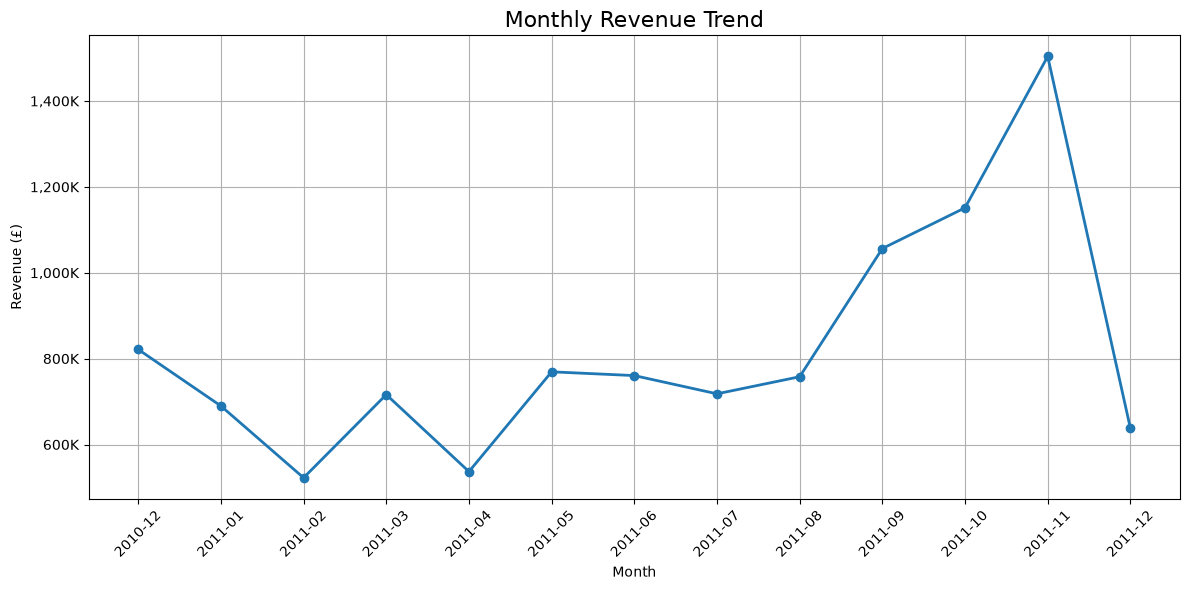

In [46]:
# Import ticker formatting tools from Matplotlib
import matplotlib.ticker as ticker

# Create the monthly revenue line chart
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue["YearMonth"],
    monthly_revenue["Revenue"],
    marker="o",
    linewidth=2
)

# Display revenue in thousands (e.g., 1,500 instead of 1.5e6)
plt.gca().yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{x/1000:,.0f}K')
)

plt.title("Monthly Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [47]:
# Group sales by country and calculate total revenue
country_revenue = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Display the top 10 revenue-generating countries
country_revenue.head(10)

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

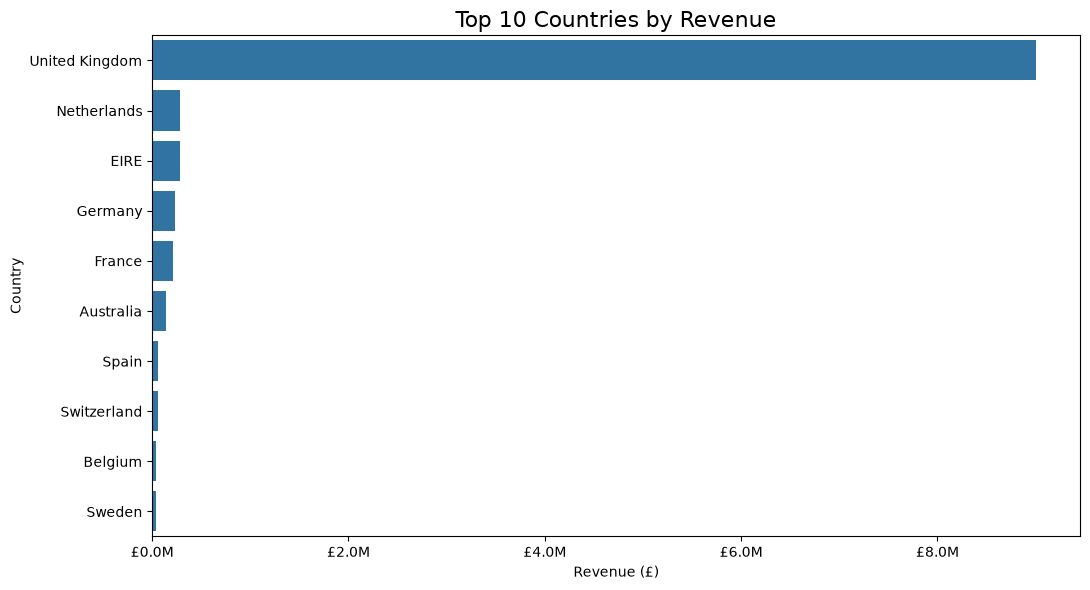

In [49]:
# Create a horizontal bar chart
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_countries,
    x="Revenue",
    y="Country"
)

# Format revenue values in millions
plt.gca().xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'£{x/1_000_000:.1f}M')
)

plt.title("Top 10 Countries by Revenue", fontsize=16)
plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [50]:
# Group sales by product description and calculate revenue
product_revenue = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Display the top 10 revenue-generating products
product_revenue.head(10)

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64

In [51]:
# Group transactions by product description and calculate total quantity
product_quantity = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

# Display the 10 products with the highest quantities sold
product_quantity.head(10)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

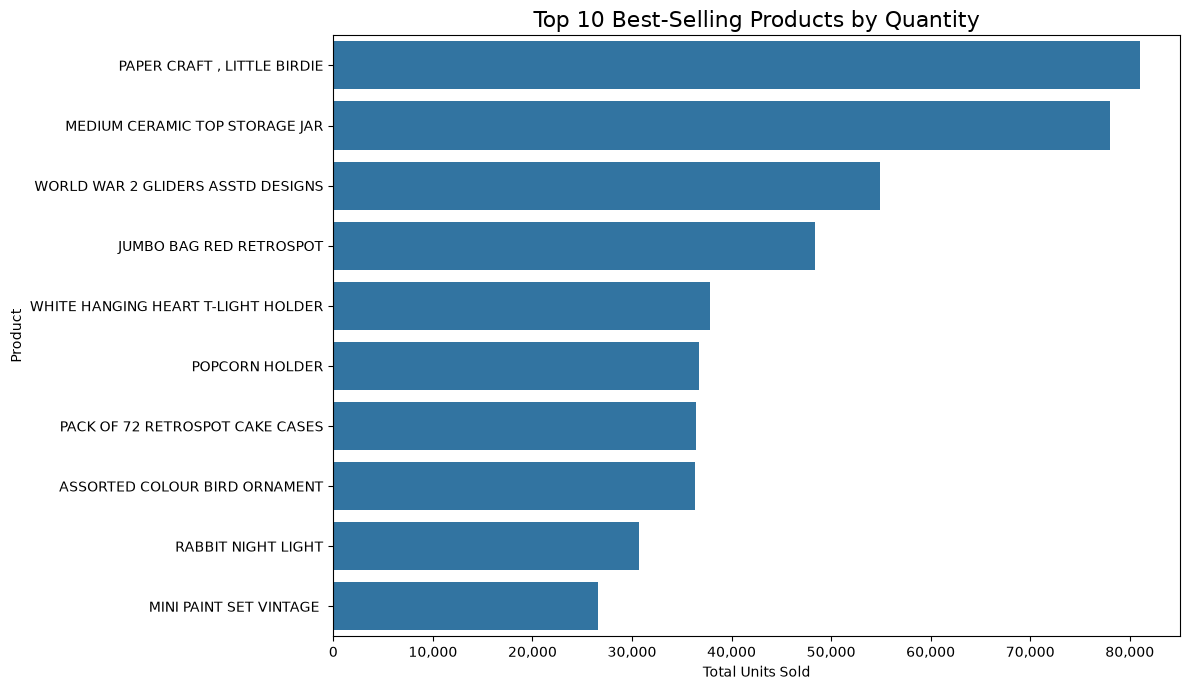

In [52]:
# Select the top 10 products by quantity sold
top_products_quantity = (
    product_quantity.head(10)
    .reset_index()
)

# Create a horizontal bar chart
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products_quantity,
    x="Quantity",
    y="Description"
)

# Add chart title and labels
plt.title("Top 10 Best-Selling Products by Quantity", fontsize=16)
plt.xlabel("Total Units Sold")
plt.ylabel("Product")

# Format quantity values with commas
plt.gca().xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'{x:,.0f}')
)

# Adjust layout and display chart
plt.tight_layout()
plt.show()

In [54]:
# Remove transactions without CustomerID
# CustomerID is essential for customer-level analysis
customer_sales = sales_df.dropna(subset=["CustomerID"]).copy()

# Group transactions by CustomerID and calculate total revenue
customer_revenue = (
    customer_sales.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Display the top 10 customers by revenue
customer_revenue.head(10)

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64

In [55]:
# Count the number of unique invoices for each customer
customer_frequency = (
    customer_sales.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

# Display the 10 most frequent customers
customer_frequency.head(10)

CustomerID
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64

In [56]:
# Set the reference date as one day after the last transaction
reference_date = sales_df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Find the latest purchase date for each customer
customer_last_purchase = (
    customer_sales.groupby("CustomerID")["InvoiceDate"]
    .max()
)

# Calculate recency in days
customer_recency = (
    reference_date - customer_last_purchase
).dt.days

# Sort customers by recency (lowest value = most recent purchase)
customer_recency = customer_recency.sort_values()

# Display the 10 most recently active customers
customer_recency.head(10)

CustomerID
17364.0    1
12433.0    1
13599.0    1
13536.0    1
16933.0    1
17581.0    1
15898.0    1
16892.0    1
17644.0    1
15910.0    1
Name: InvoiceDate, dtype: int64

In [57]:
# Group sales transactions by customer and calculate RFM metrics
rfm = customer_sales.groupby("CustomerID").agg(
    RecencyDate=("InvoiceDate", "max"),  # Latest purchase date
    Frequency=("InvoiceNo", "nunique"),  # Number of unique orders
    Monetary=("Revenue", "sum")          # Total customer spending
)

# Calculate Recency as days since the latest purchase
rfm["Recency"] = (
    reference_date - rfm["RecencyDate"]
).dt.days

# Arrange columns in standard RFM order
rfm = rfm[["Recency", "Frequency", "Monetary"]]

# Display the first five customers
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [58]:
# Generate statistical summaries of the RFM metrics
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


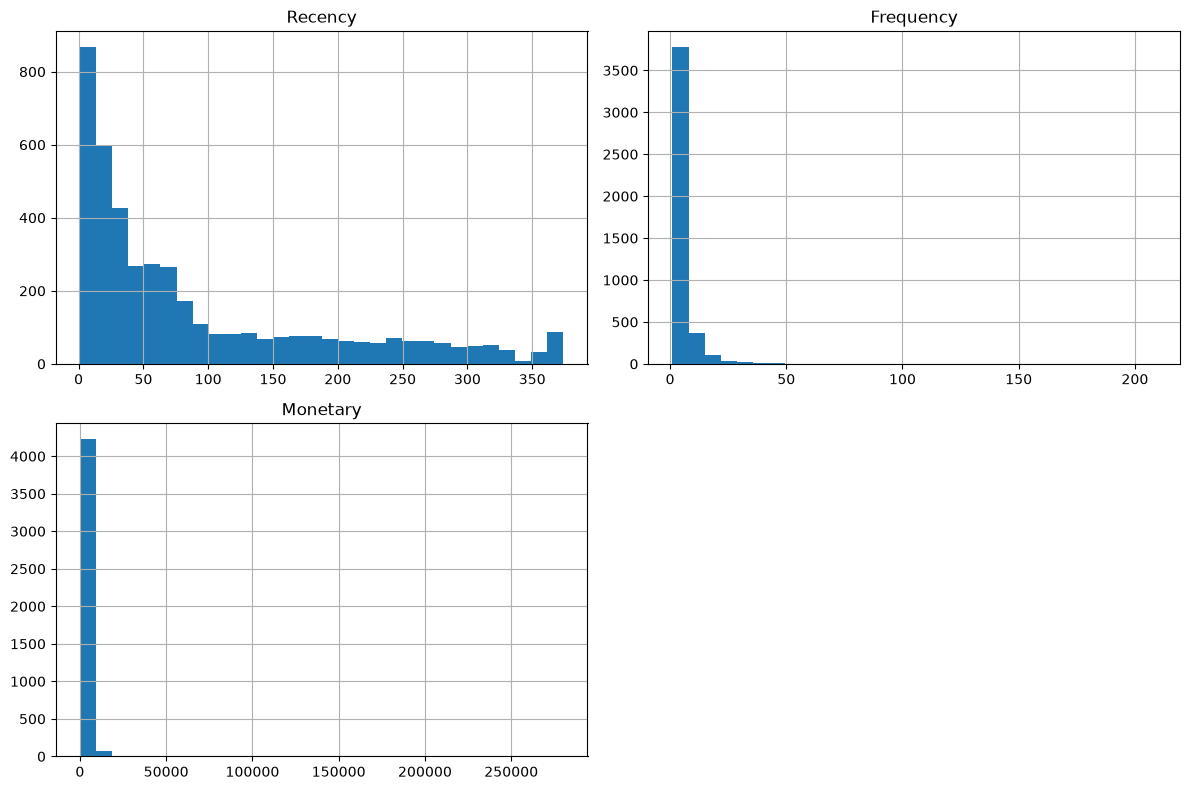

In [59]:
# Create a histogram for each RFM feature
# Histograms help us understand the distribution of customer data

rfm[["Recency", "Frequency", "Monetary"]].hist(
    figsize=(12, 8),
    bins=30
)

# Add spacing between the histogram plots
plt.tight_layout()

# Display all three histograms
plt.show()

In [60]:
# Import StandardScaler from Scikit-learn
from sklearn.preprocessing import StandardScaler

In [61]:
# Create the scaler object
scaler = StandardScaler()

# Fit the scaler and transform the RFM data
rfm_scaled = scaler.fit_transform(rfm)

# Convert the scaled array back into a DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=rfm.columns,
    index=rfm.index
)

# Display the first five scaled customer records
rfm_scaled.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,2.334574,-0.425097,8.363010
12347.0,-0.905340,0.354417,0.251699
12348.0,-0.175360,-0.035340,-0.027988
12349.0,-0.735345,-0.425097,-0.032406
12350.0,2.174578,-0.425097,-0.190812


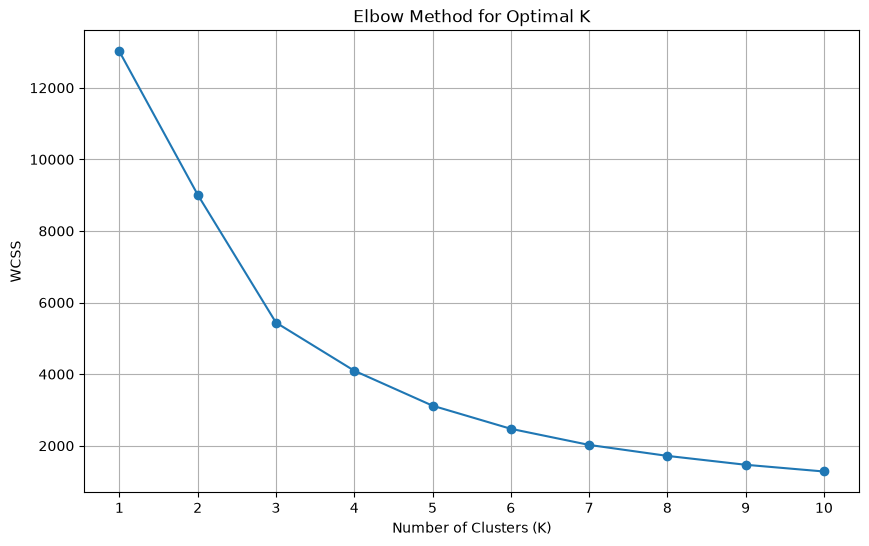

In [62]:
# Import KMeans clustering algorithm
from sklearn.cluster import KMeans

# Store the Within-Cluster Sum of Squares (WCSS) values
wcss = []

# Test different cluster counts from 1 to 10
for i in range(1, 11):

    # Create a K-Means model with i clusters
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    # Fit the model using our scaled RFM data
    kmeans.fit(rfm_scaled)

    # Store the model's inertia (WCSS)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Method graph
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker="o")

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [63]:
# Create the final K-Means model with 3 customer clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train the model and assign a cluster to each customer
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

# Display the first 10 customers with their assigned clusters
rfm.head(10)

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,326,1,77183.60,0
12347.0,2,7,4310.00,1
12348.0,75,4,1797.24,1
12349.0,19,1,1757.55,1
12350.0,310,1,334.40,0
12352.0,36,8,2506.04,1
12353.0,204,1,89.00,0
12354.0,232,1,1079.40,0
12355.0,214,1,459.40,0


In [64]:
# Calculate the average RFM values for each customer cluster
cluster_summary = rfm.groupby("Cluster").agg(
    Recency=("Recency", "mean"),
    Frequency=("Frequency", "mean"),
    Monetary=("Monetary", "mean"),
    Customer_Count=("Cluster", "count")
).round(2)

# Display the cluster summary
cluster_summary


,Recency,Frequency,Monetary,Customer_Count
Cluster,,,,
0,247.11,1.58,629.66,1082
1,41.45,4.67,1849.67,3230
2,6.04,66.42,85826.08,26


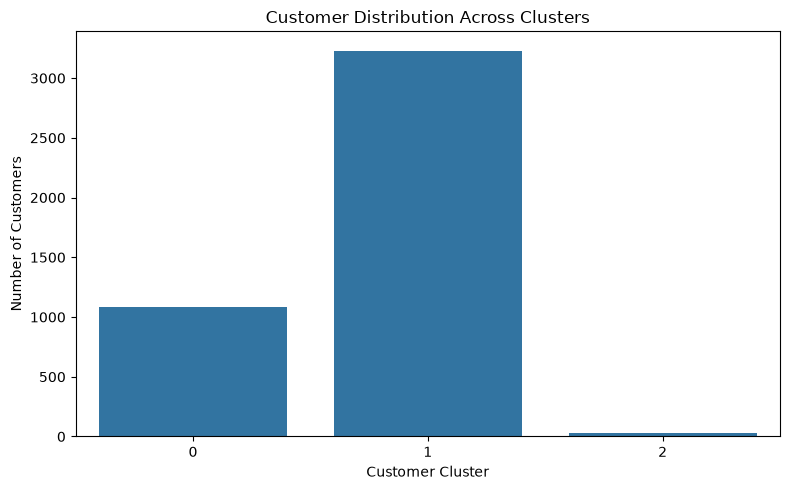

In [65]:
# Count the number of customers in each cluster
cluster_counts = rfm["Cluster"].value_counts().sort_index()

# Create a bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

# Add chart labels and title
plt.title("Customer Distribution Across Clusters")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")

# Display the chart
plt.tight_layout()
plt.show()

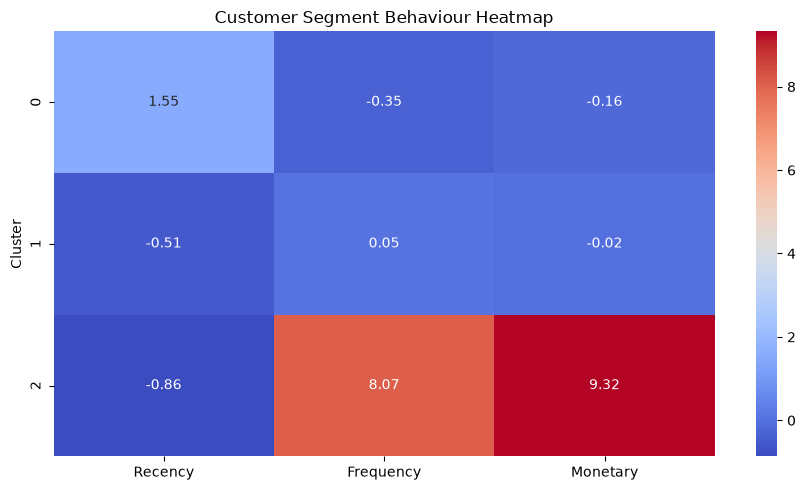

In [66]:
# Attach cluster labels to the scaled RFM data
rfm_with_clusters = rfm_scaled.copy()
rfm_with_clusters["Cluster"] = rfm["Cluster"]

# Calculate average scaled RFM values for each cluster
cluster_profile = rfm_with_clusters.groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean()

# Create the heatmap
plt.figure(figsize=(9, 5))

sns.heatmap(
    cluster_profile,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

# Add chart title
plt.title("Customer Segment Behaviour Heatmap")

plt.tight_layout()
plt.show()

In [67]:
# Add each customer's cluster number to the sales dataset
dashboard_df = sales_df.merge(
    rfm[["Cluster"]],
    left_on="CustomerID",
    right_index=True,
    how="left"
)

# Display the first five records
dashboard_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,YearMonth,Cluster
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12,0.0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,0.0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12,0.0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,0.0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,0.0


In [68]:
# Save the dashboard-ready dataset inside the data folder
dashboard_df.to_csv(
    BASE_DIR / "data" / "shoplytics_dashboard.csv",
    index=False
)

print("Dashboard dataset saved successfully!")

Dashboard dataset saved successfully!


In [69]:
# Load the dashboard dataset
dashboard_check = pd.read_csv(
    BASE_DIR / "data" / "shoplytics_dashboard.csv"
)

# Calculate the number of unique invoices
print("Unique Orders:", dashboard_check["InvoiceNo"].nunique())

# Count the total transaction rows
print("Total Transaction Rows:", len(dashboard_check))

# Check for missing invoice numbers
print("Missing Invoice Numbers:", dashboard_check["InvoiceNo"].isna().sum())

# Display the number of unique invoices in our original sales dataset
print("Original Sales Orders:", sales_df["InvoiceNo"].nunique())

C:\Users\revat\AppData\Local\Temp\ipykernel_20396\1173059969.py:2: DtypeWarning: Columns (0: InvoiceNo) have mixed types. Specify dtype option on import or set low_memory=False.
  dashboard_check = pd.read_csv(


Unique Orders: 19962
Total Transaction Rows: 524878
Missing Invoice Numbers: 0
Original Sales Orders: 19960


In [70]:
# Get unique invoice numbers from both datasets
dashboard_invoices = set(dashboard_check["InvoiceNo"].unique())
sales_invoices = set(sales_df["InvoiceNo"].unique())

# Find invoices present only in the dashboard dataset
extra_invoices = dashboard_invoices - sales_invoices

# Display the extra invoice numbers
print("Extra invoices:", extra_invoices)

# Display their transaction records
dashboard_check[
    dashboard_check["InvoiceNo"].isin(extra_invoices)
]

Extra invoices: {557056, 557057, 557058, 557063, 557064, 557065, 557066, 557067, 557068, 557069, 557070, 557089, 557092, 573142, 557100, 557103, 557109, 557110, 557112, 557113, 557114, 557115, 557116, 557117, 557118, 557119, 557120, 557121, 557122, 557123, 557124, 557125, 557126, 557127, 557128, 557129, 557130, 557131, 557132, 557133, 557134, 557135, 557136, 557140, 557141, 557143, 557144, 557145, 557146, 557147, 576239, 557149, 557150, 557151, 557152, 557153, 573156, 573158, 579672, 573160, 579673, 573161, 579674, 579675, 573163, 579676, 573164, 579677, 557208, 573165, 557210, 557211, 557212, 557213, 557214, 557215, 557216, 557217, 557218, 557219, 557220, 557221, 557222, 557223, 573167, 557225, 557226, 557227, 557228, 557229, 557230, 557231, 557232, 557233, 557235, 557237, 573171, 579684, 579685, 557247, 557248, 573173, 557250, 557251, 557252, 557253, 557254, 557255, 557256, 557257, 557258, 557259, 557260, 557261, 557262, 557263, 557264, 557265, 557266, 557267, 557268, 573177, 557270,

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,YearMonth,Cluster
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12,0.0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,0.0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12,0.0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,0.0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12,0.0
...,...,...,...,...,...,...,...,...,...,...,...
524873,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20,2011-12,1.0
524874,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60,2011-12,1.0
524875,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011-12,1.0
524876,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,2011-12,1.0


In [71]:
# Display only the extra invoice numbers
print("Extra invoices:", extra_invoices)

# Display only the invoice numbers and their row counts
print(
    dashboard_check[
        dashboard_check["InvoiceNo"].isin(extra_invoices)
    ].groupby("InvoiceNo").size()
)

Extra invoices: {557056, 557057, 557058, 557063, 557064, 557065, 557066, 557067, 557068, 557069, 557070, 557089, 557092, 573142, 557100, 557103, 557109, 557110, 557112, 557113, 557114, 557115, 557116, 557117, 557118, 557119, 557120, 557121, 557122, 557123, 557124, 557125, 557126, 557127, 557128, 557129, 557130, 557131, 557132, 557133, 557134, 557135, 557136, 557140, 557141, 557143, 557144, 557145, 557146, 557147, 576239, 557149, 557150, 557151, 557152, 557153, 573156, 573158, 579672, 573160, 579673, 573161, 579674, 579675, 573163, 579676, 573164, 579677, 557208, 573165, 557210, 557211, 557212, 557213, 557214, 557215, 557216, 557217, 557218, 557219, 557220, 557221, 557222, 557223, 573167, 557225, 557226, 557227, 557228, 557229, 557230, 557231, 557232, 557233, 557235, 557237, 573171, 579684, 579685, 557247, 557248, 573173, 557250, 557251, 557252, 557253, 557254, 557255, 557256, 557257, 557258, 557259, 557260, 557261, 557262, 557263, 557264, 557265, 557266, 557267, 557268, 573177, 557270,

In [72]:
print(len(extra_invoices))

17327


In [73]:
# Compare invoice number data types
print("Dashboard:", dashboard_check["InvoiceNo"].dtype)
print("Original:", sales_df["InvoiceNo"].dtype)

Dashboard: object
Original: str
